# Support Device Inpainting with Cheff

This notebook shows how to remove support devices by converting a 256x256 segmentation mask into the 64x64 latent-space mask expected by Cheff.

In [1]:
import os
os.chdir('..')

import torch
import torch.nn.functional as F
from PIL import Image
from torchvision.utils import make_grid
from torchvision.transforms.functional import to_pil_image, to_tensor, resize
from torchvision.transforms import InterpolationMode

## Load Cheff LDM

For inpainting, the same unconditional LDM can be used.

In [2]:
from cheff import CheffLDM

device = 'cuda'
sdm_path = 'trained_models/cheff_diff_uncond.pt'
ae_path = 'trained_models/cheff_autoencoder.pt'

cheff_ldm = CheffLDM(model_path=sdm_path, ae_path=ae_path, device=device)

## Load the Input Image and a 256x256 Segmentation Mask

The image is expected to be 256x256. The segmentation mask should also be 256x256, where white indicates support-device pixels.

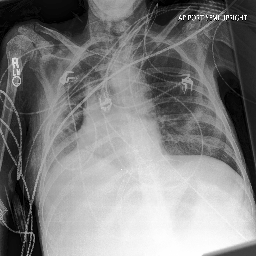

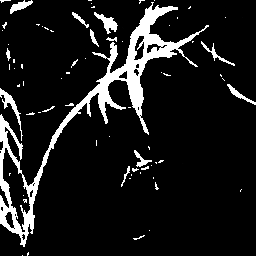

In [7]:
img_path = 'outputs/cxr_seg/train_patient00067_study2_view1_frontal/original_256.png'
seg_mask_path = 'outputs/cxr_seg/train_patient00067_study2_view1_frontal/mask_256.png'

img = Image.open(img_path).convert('L')
seg_mask = Image.open(seg_mask_path).convert('L')

display(img)
display(seg_mask)

img = to_tensor(img).to(device)
img = img * 2 - 1

if img.shape[0] == 1:
    img = img.expand(3, -1, -1)

## Convert the 256x256 Segmentation Mask into a 64x64 Inpainting Mask

Cheff inpainting expects a binary mask in latent space. In the segmentation mask, white means device. In the inpainting mask, zero means regenerate this region.

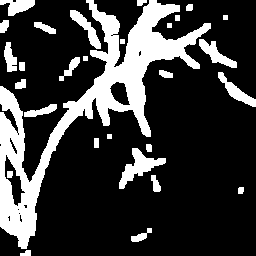

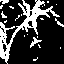

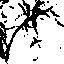

In [8]:
seg_mask_256 = to_tensor(seg_mask)
seg_mask_256 = (seg_mask_256 > 0.5).float()

# Optional: dilate the segmentation mask so thin tubes and lines are fully covered.
dilation = 5
pad = dilation // 2
seg_mask_256 = F.max_pool2d(seg_mask_256.unsqueeze(0), kernel_size=dilation, stride=1, padding=pad).squeeze(0)
seg_mask_256 = (seg_mask_256 > 0.0).float()

device_mask_64 = resize(seg_mask_256, [64, 64], interpolation=InterpolationMode.NEAREST)
device_mask_64 = (device_mask_64 > 0.5).float()

# Cheff uses 1 to keep the original content and 0 to regenerate it.
inpaint_mask_64 = 1.0 - device_mask_64
inpaint_mask_64 = inpaint_mask_64.to(device)

display(to_pil_image(seg_mask_256.cpu()))
display(to_pil_image(device_mask_64.cpu()))
display(to_pil_image(inpaint_mask_64.cpu()))

## Run Inpainting

The image stays at 256x256, while the mask is expanded from 64x64 latent space to the batch shape expected by `sample_inpaint`.

Data shape for DDIM sampling is (4, 3, 64, 64), eta 1.0
Running DDIM Sampling with 100 timesteps


DDIM Sampler: 100%|██████████████████████████████████████████████████████████████████| 100/100 [00:07<00:00, 13.80it/s]


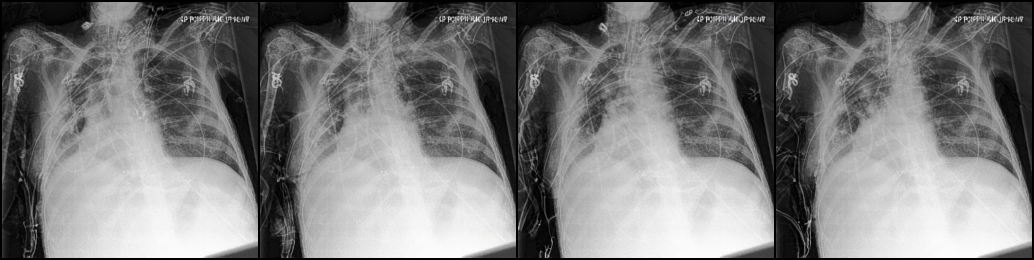

In [9]:
imgs = img.unsqueeze(0).expand(4, -1, -1, -1)
masks = inpaint_mask_64.unsqueeze(0).expand(4, -1, -1, -1)

imgs_edited = cheff_ldm.sample_inpaint(
    target_img=imgs,
    mask=masks,
    sampling_steps=100,
)

imgs_edited.clamp_(-1, 1)
imgs_edited = (imgs_edited + 1) / 2

img_grid = make_grid(imgs_edited.cpu())
display(to_pil_image(img_grid))

## Compare the Original Image and the Edited Outputs

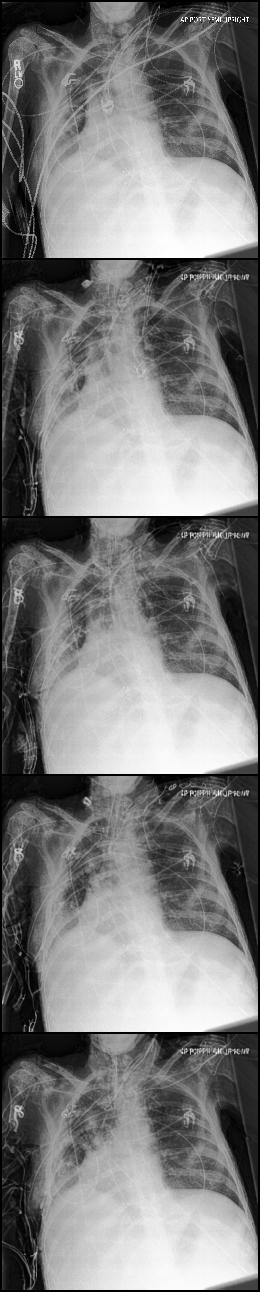

In [10]:
original = ((img.detach().cpu() + 1) / 2).unsqueeze(0)
original = original[:, :1]
edited = imgs_edited[:, :1].cpu()
comparison = torch.cat([original, edited], dim=0)
comparison_grid = make_grid(comparison, nrow=1)
display(to_pil_image(comparison_grid))

## mask segmentation training
dataset
* Train size: 3000
* Valid size: 300
* Test size: 3000

Unet++的優勢
* 填補資訊斷層：Unet++ 引入了 Nested Skips 和 Dense Convolution Blocks。它在 Encoder（收縮路徑）和 Decoder（擴張路徑）之間加了很多「小橋樑」。
* 對細小物體更敏感：這些小橋樑能讓深層的語義資訊（這是一個物體）和淺層的細節資訊（這是一個邊界）結合得更緊密。對於我擔心的導管斷裂、線條模糊問題，Unet++ 的修正能力比 Unet 強很多。

我的任務是「小 pacemaker + 細長 lead」

* 第一個先跑：Unet++ + ResNet34
* 主力模型：Unet++ + EfficientNet-B3
* 想再追效果：Unet++ + ConvNeXt-Tiny

Unet++ + ResNet-34
* 定位：Baseline
* X-ray 主要是灰階、對比度特徵。ResNet-34 的 34 層深度足以提取這些特徵。
* Unet++ 因為內部結構複雜，顯存佔用比 Unet 高。搭配輕量級的 ResNet-34 可以確保你的 GPU 能跑得動較大的 Batch Size，穩定性較高。

Unet++ + EfficientNet-B3
* 複合縮放 (Compound Scaling)：EfficientNet 同時針對寬度、深度和解析度進行優化。相較於 ResNet，它能以更少的參數捕捉到更細膩的語義特徵。
* 對細小物體極其敏感：EfficientNet-B3 的特徵提取非常精準。在 X-ray 中，醫護人員放置的設備（如 1-2mm 的導線）在 B3 的特徵圖中能比 ResNet 保留更多的細節。
* 優化後的感受野：它能更好地平衡「看局部細節」與「看全局解剖結構」之間的關係。

Unet++ + ConvNeXt-Tiny
* 定位：SOTA Seeker
* 純卷積的巔峰：ConvNeXt 是由 Meta AI 提出的架構，目的是讓純卷積網路（CNN）達到類似 Transformer (ViT) 的效果。它使用了更大的卷積核（7x7）和更先進的結構，感受野（Receptive Field）極大。
* 全域語義強：對於長條形的 Support Device（如從喉部延伸到心臟的導管），ConvNeXt 更有能力理解這種「跨區域」的連續物體，大幅減少斷連現象。
* 處理醫療器材的高對比度：ConvNeXt 借鑑了 Transformer 的 LayerNorm 和改進的激活函數，在處理 X-ray 中極高亮度（金屬）與極低亮度（肺部）之間的邊界時，適應力更強。
